# QuantLab · investigación cuantitativa reproducible

**BTC/USDT · 4 horas · 2022–2024**

¿Persisten comportamientos interesantes tras costos, riesgo y evaluación fuera de muestra?

Esta narrativa explora el experimento ya definido; no optimiza contra los resultados finales. Las cifras son descriptivas y no prueban rentabilidad futura.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.config import Config
from src.data.loader import load
from src.features.indicators import features, distribution
from src.strategies.momentum import Momentum
from src.strategies.mean_reversion import MeanReversion
from src.experiments.parameter_sensitivity import split
from src.backtest.engine import run
from src.analysis.metrics import metrics
config = Config()
data, quality, provenance = load(ROOT/"data/raw/btcusdt_4h.csv")
selection = json.loads((ROOT/"reports/selection.json").read_text())
assert quality["sha256"] == selection["dataset_sha256"], "Regenerar informe: cambió el dataset"
print(provenance["kind"], provenance["source"])
display(pd.Series(quality), data.head())

historical Binance public spot archives


rows                                                           6576
duplicates                                                        0
missing_bars                                                      0
missing_values                                                    0
input_sorted                                                   True
frequency                                                        4h
policy             sort; fail on duplicates, gaps or missing values
sha256            a13e78bab409c5bc5eaac45804d2a82235a2f70aa7fb4c...
dtype: object

,open,high,low,close,volume
timestamp,,,,,
2022-01-01 00:00:00+00:00,46216.93,46949.99,46208.37,46813.20,3495.20465
2022-01-01 04:00:00+00:00,46813.21,47555.55,46591.23,47194.73,3522.79888
2022-01-01 08:00:00+00:00,47194.73,47344.69,46715.39,46758.87,2729.67811
2022-01-01 12:00:00+00:00,46758.87,47491.14,46756.30,47219.04,3055.90946
2022-01-01 16:00:00+00:00,47219.04,47954.63,47186.07,47329.78,4061.67681


## 1. Calidad e interpretación temporal

Las fechas indican aperturas UTC. Rechazamos huecos, duplicados y valores inválidos: rellenarlos sin criterio podría crear retornos artificiales. El CSV conserva las seis columnas OHLCV; sus checksums se registran junto a la fuente.

,split,start_open_utc,last_open_utc,end_exclusive_utc,bars
0,train,2022-01-01 00:00:00+00:00,2023-10-20 08:00:00+00:00,2023-10-20 12:00:00+00:00,3945
1,validation,2023-10-20 12:00:00+00:00,2024-05-26 12:00:00+00:00,2024-05-26 16:00:00+00:00,1315
2,test,2024-05-26 16:00:00+00:00,2024-12-31 20:00:00+00:00,2025-01-01 00:00:00+00:00,1316


,retornos
mean,0.000168
median,0.000159
std,0.011186
skewness,0.037387
excess_kurtosis,7.018764
q0.01,-0.032463
q0.05,-0.017348
q0.25,-0.004058
q0.75,0.004362
q0.95,0.017192


,volumen
count,6576.000000
mean,15661.138069
std,20977.019178
min,526.414130
25%,3746.206863
50%,7022.764750
75%,19133.047592
max,284711.694213


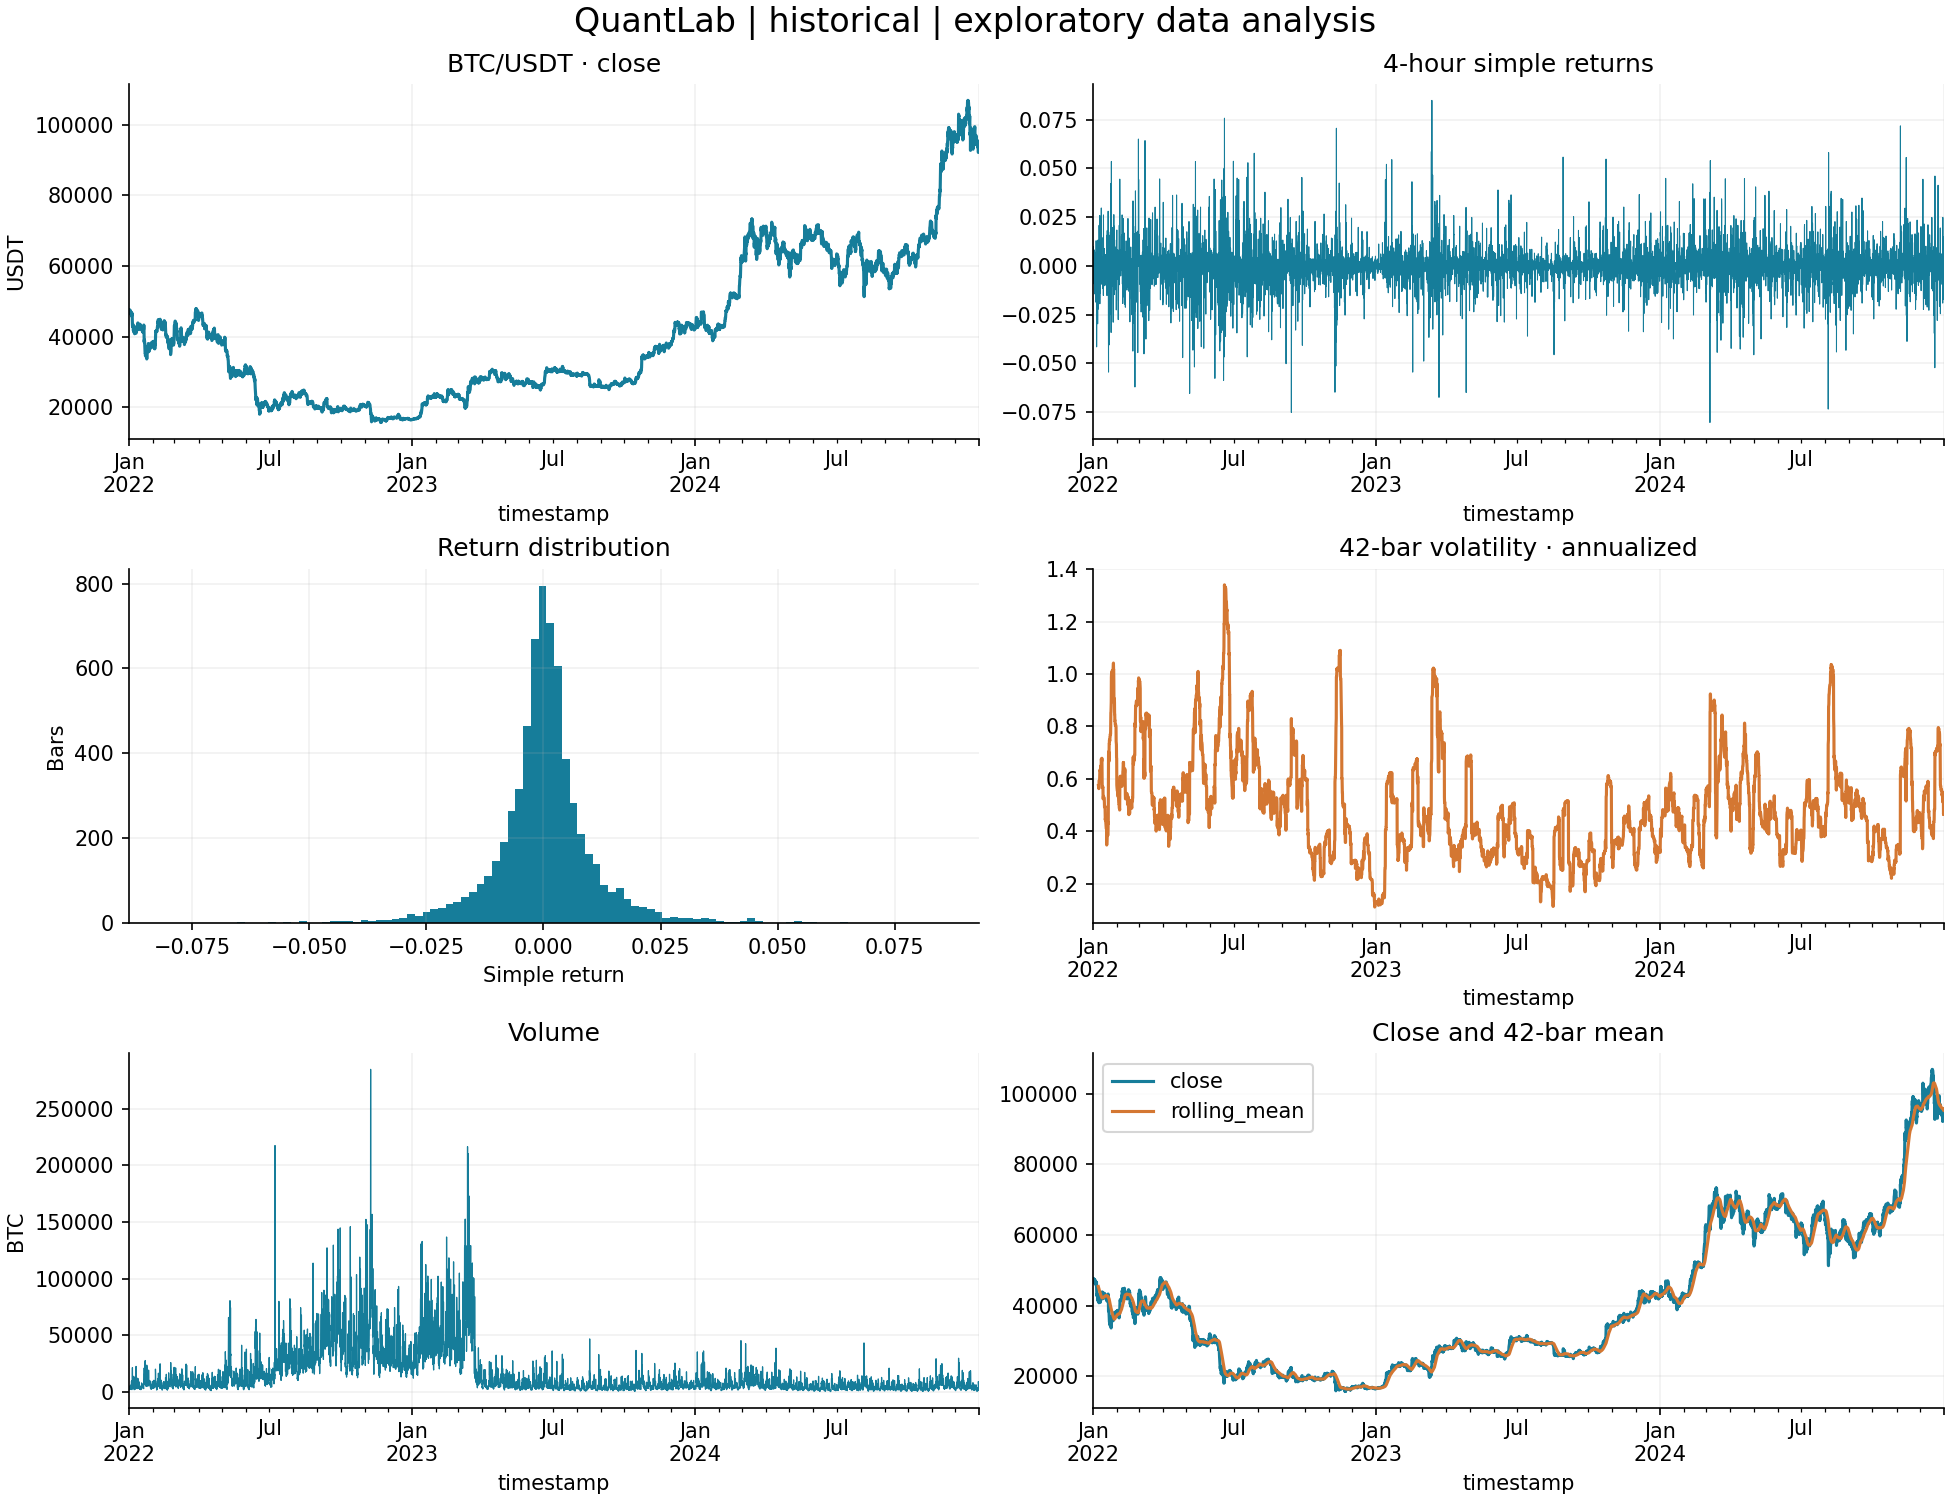

In [2]:
parts = split(data)
display(pd.read_csv(ROOT/"reports/splits.csv"))
f = features(data, config.periods_per_year)
display(distribution(f.simple_return).to_frame("retornos"), data.volume.describe().to_frame("volumen"))
display(Image(filename=str(ROOT/"reports/figures/exploration.png")))

## 2. Hipótesis y señales causales

Momentum: una tendencia puede persistir. Reversión: una desviación puede corregirse. Ninguna hipótesis garantiza ganancias.

A continuación se ejecuta una demostración **solo en entrenamiento**. Los algoritmos están en módulos reutilizables; no se implementa el motor dentro del notebook.

In [3]:
train = parts["train"]
strategies = {"momentum": Momentum(**selection["parameters"]), "mean_reversion": MeanReversion()}
training = {}
for name, strategy in strategies.items():
    signals = strategy.generate_signals(train)
    training[name] = metrics(run(train, signals, fee=config.fee), config.periods_per_year)
training["buy_hold"] = metrics(run(train, pd.Series(1,index=train.index), fee=config.fee, benchmark=True), config.periods_per_year)
display(pd.DataFrame(training).T)

,total_return,annualized_return,annualized_volatility,sharpe,max_drawdown,calmar,win_rate,trades,average_trade,best_trade,worst_trade,exposure,profit_factor,fees_paid,turnover
momentum,-0.296687,-0.177589,0.332113,-0.422314,-0.567110,-0.313147,0.233333,60.0,-0.003762,0.382650,-0.092269,0.444360,0.695441,805.445071,805445.071305
mean_reversion,-0.420613,-0.261542,0.317375,-0.796521,-0.576892,-0.453364,0.621622,37.0,-0.011922,0.066502,-0.276706,0.252725,0.466490,450.388770,450388.769664
buy_hold,-0.355639,-0.216627,0.536860,-0.186297,-0.672139,-0.322295,0.000000,1.0,-0.355639,-0.355639,-0.355639,1.000000,0.000000,16.440066,16440.066240


## 3. Selección y costos

El motor aplica señal al cierre t en apertura t+1. Mantiene unidades, cobra por lado y liquida al final. El benchmark usa los mismos costos. El histórico de entrenamiento de la configuración elegida es retrospectivo.

Solo nueve candidatos: elección por Sharpe neto de validación. El período test no se pasa a la función de selección.

{'strategy': 'momentum',
 'parameters': {'fast': 10, 'slow': 50},
 'selection': 'highest validation net Sharpe, ties lower fast then slow',
 'candidates': 9,
 'train_end': '2023-10-20 08:00:00+00:00',
 'validation_end': '2024-05-26 12:00:00+00:00',
 'test_start': '2024-05-26 16:00:00+00:00',
 'dataset_sha256': 'a13e78bab409c5bc5eaac45804d2a82235a2f70aa7fb4c6b3b81b86cb94cd923'}

,split,fast,slow,total_return,sharpe,max_drawdown
0,train,10,50,-0.296687,-0.422314,-0.567110
1,validation,10,50,0.925761,2.947520,-0.137444
2,train,10,100,-0.138060,-0.104302,-0.389716
3,validation,10,100,0.902687,2.807625,-0.234136
4,train,10,150,-0.254658,-0.351166,-0.482362
5,validation,10,150,0.562099,1.982326,-0.324708
6,train,20,50,-0.174946,-0.162975,-0.509510
7,validation,20,50,0.749379,2.567841,-0.226552
8,train,20,100,-0.045925,0.080330,-0.379958
9,validation,20,100,0.809708,2.606811,-0.247835


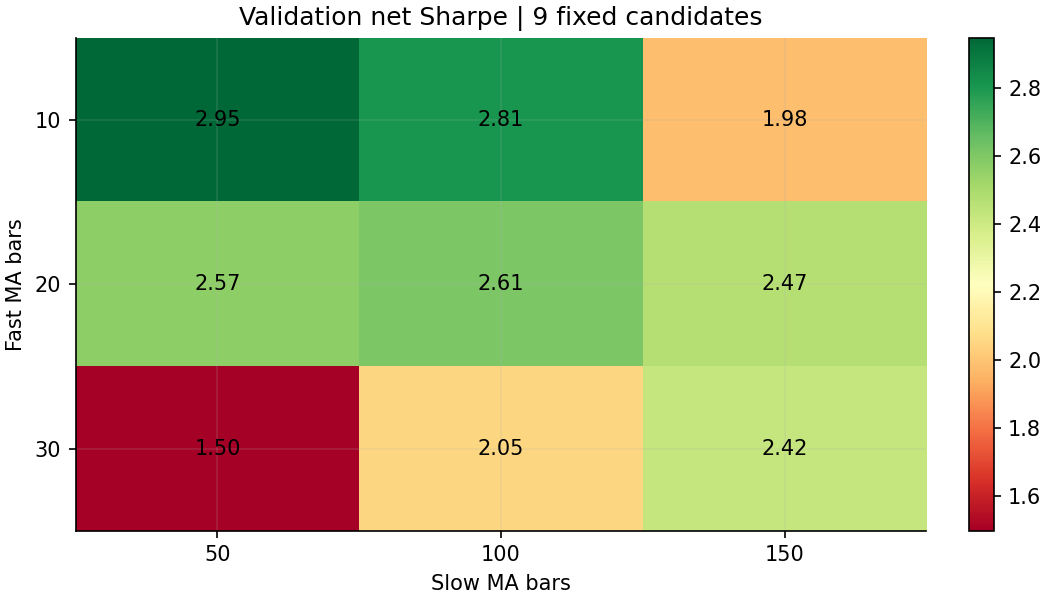

In [4]:
display(selection)
display(pd.read_csv(ROOT/"reports/parameter_sensitivity.csv")[["split","fast","slow","total_return","sharpe","max_drawdown"]])
display(Image(filename=str(ROOT/"reports/figures/sensitivity.png")))

## 4. Evidencia fuera de muestra y drawdown

Leemos los resultados congelados por la ejecución del protocolo, sin volver a seleccionar parámetros. Las tres carteras parten del mismo capital en cada división. Un retorno alto con un drawdown profundo implica una experiencia de riesgo muy distinta.

,split,strategy,total_return,sharpe,max_drawdown,exposure,trades
0,train,momentum,-0.296687,-0.422314,-0.567110,0.444360,60.0
2,train,mean_reversion,-0.420613,-0.796521,-0.576892,0.252725,37.0
4,train,buy_hold,-0.355639,-0.186297,-0.672139,1.000000,1.0
6,validation,momentum,0.925761,2.947520,-0.137444,0.657795,17.0
8,validation,mean_reversion,0.141721,1.028766,-0.120833,0.146768,10.0
10,validation,buy_hold,1.302629,3.023106,-0.224450,1.000000,1.0
12,test,momentum,0.189533,1.000272,-0.199032,0.548632,16.0
14,test,mean_reversion,0.014277,0.228767,-0.264281,0.247720,12.0
16,test,buy_hold,0.356453,1.258452,-0.283961,1.000000,1.0


,strategy,scenario,total_return,fees_paid
12,momentum,net,0.189533,330.806809
13,momentum,frictionless,0.228213,0.000000
14,mean_reversion,net,0.014277,233.075610
15,mean_reversion,frictionless,0.038914,0.000000
16,buy_hold,net,0.356453,23.568116
17,buy_hold,frictionless,0.359168,0.000000


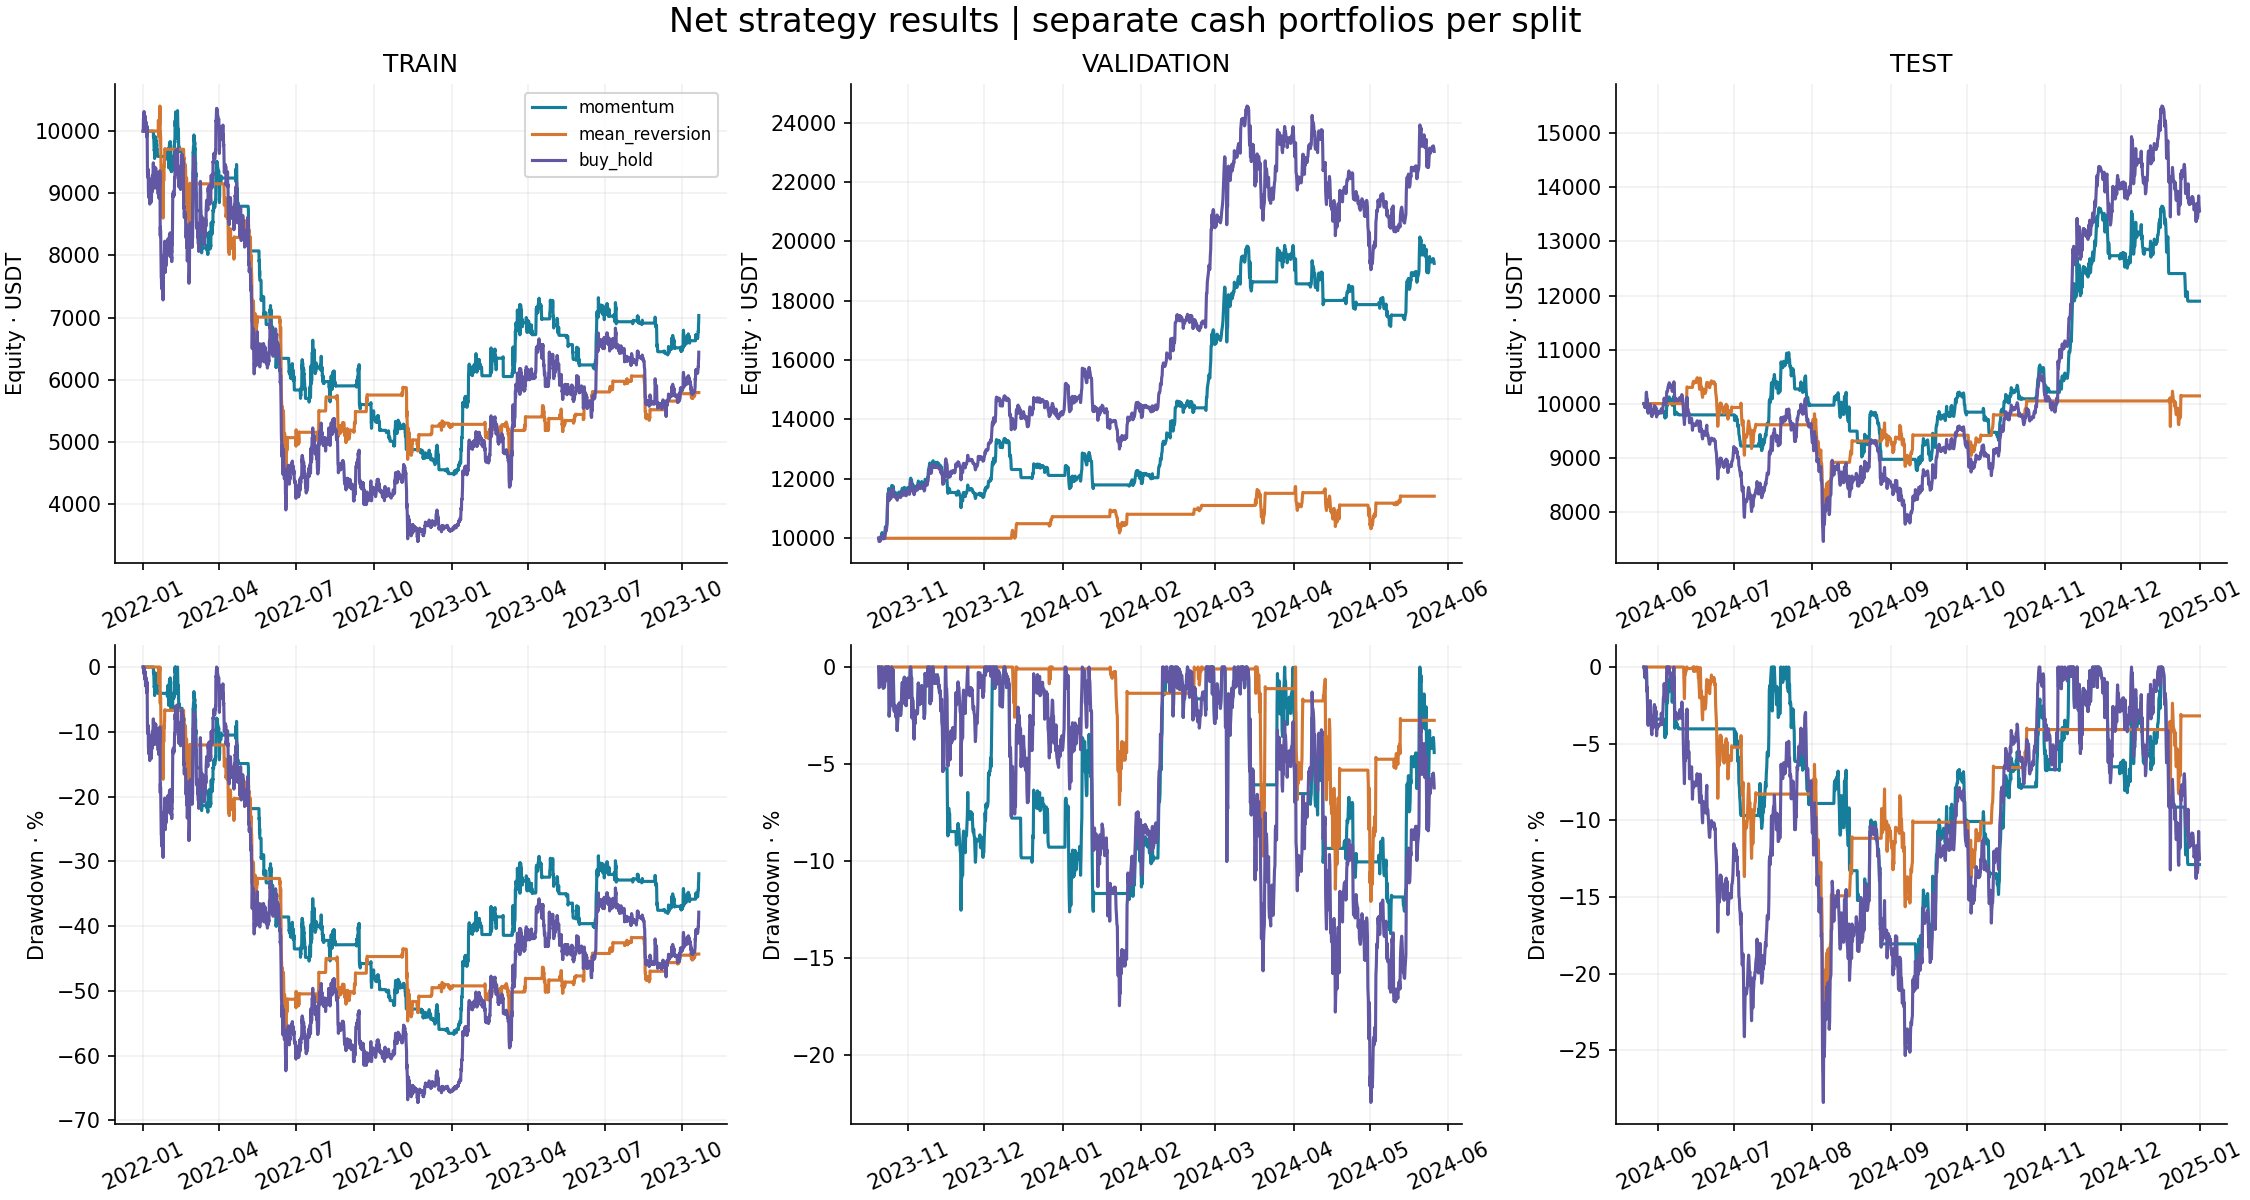

In [5]:
results = pd.read_csv(ROOT/"reports/metrics.csv")
net = results[results.scenario == "net"]
display(net[["split","strategy","total_return","sharpe","max_drawdown","exposure","trades"]])
display(results[results.split == "test"][["strategy","scenario","total_return","fees_paid"]])
display(Image(filename=str(ROOT/"reports/figures/equity_drawdown.png")))

## 5. Riesgo y regímenes

VaR histórico no es la máxima pérdida. Los regímenes son conocidos al inicio de la vela, mediante indicadores retrasados. Sus medias condicionales no son efectos causales ni rentabilidades de carteras independientes.

In [6]:
risk = pd.read_csv(ROOT/"reports/risk.csv")
regimes = pd.read_csv(ROOT/"reports/regimes.csv")
display(risk[risk.split == "test"])
display(regimes[regimes.split == "test"])

,split,strategy,bar_var95_loss,bar_expected_shortfall95_loss,worst_bar,worst_6bar_compounded,negative_bar_fraction,downside_rms
6,test,momentum,0.011381,0.019011,-0.044156,-0.068381,0.280395,0.005101
7,test,mean_reversion,0.006870,0.017138,-0.073419,-0.156923,0.122340,0.004607
8,test,buy_hold,0.017250,0.024772,-0.073419,-0.156923,0.476444,0.007407


,regime,bars,mean_bar_return,bar_volatility,exposure,worst_bar,split,strategy
27,down / high_vol,385,0.000031,0.006409,0.296104,-0.044156,test,momentum
28,down / low_vol,128,-0.000283,0.003194,0.171875,-0.018467,test,momentum
29,up / high_vol,290,0.001109,0.010124,0.868966,-0.038734,test,momentum
30,up / low_vol,513,-0.000169,0.007197,0.651072,-0.043268,test,momentum
31,down / high_vol,385,0.000216,0.009839,0.483117,-0.073419,test,mean_reversion
32,down / low_vol,128,-0.000050,0.009107,0.710938,-0.034895,test,mean_reversion
33,up / high_vol,290,-0.000259,0.002223,0.024138,-0.025041,test,mean_reversion
34,up / low_vol,513,0.000076,0.002935,0.081871,-0.027332,test,mean_reversion
35,down / high_vol,385,0.000255,0.012705,1.000000,-0.073419,test,buy_hold
36,down / low_vol,128,-0.000415,0.010112,1.000000,-0.034895,test,buy_hold


## 6. Conclusiones

En test, momentum obtiene 18,95% neto, reversión 1,43% y comprar/mantener 35,65%. Momentum reduce el drawdown máximo al 19,90% frente al 28,40% del benchmark, con aproximadamente la mitad de exposición. Reversión mantiene un drawdown de 26,43% pese a su retorno reducido.

Momentum presenta su mayor media por vela en el régimen alcista de alta volatilidad; las diferencias son descriptivas y las muestras de regímenes tienen distinto tamaño. La fuerte caída de resultados entre validación y test es una razón para evitar extrapolar la selección.

**No hay evidencia estadística suficiente para afirmar una ventaja.** Un activo, nueve comparaciones de validación y un solo período reservado no establecen generalización. Usar ahora estos resultados para rediseñar el modelo exige reservar un nuevo test.

For educational and research purposes. Historical performance does not imply future results.